# 🎓 Student Performance Prediction using Machine Learning
**Subject:** Machine Learning (5th Semester PBL)

**Goal:** Predict a student's final marks from 7 academic and behavioural factors, and find out which factors matter the most.

**Type of problem:** *Supervised learning → Regression* (we predict a number, the final marks).

### Steps in this notebook
1. Import libraries
2. Load the dataset (from the `data/` folder)
3. Understand the data
4. Clean the data (preprocessing)
5. Exploratory Data Analysis (EDA)
6. Split data into training and testing sets
7. Train machine learning models
8. Evaluate the models
9. Feature importance (which factors matter most?)
10. Save the model
11. Predict for a new student (7 questions)
12. Conclusion

> **How to run:** in VS Code click *Run All*. In Google Colab use *Runtime → Run all*. If you use Colab, cell 2 will ask you to upload the CSV from the `data/` folder.

## Step 1: Import libraries
These are the tools we need:
- **pandas / numpy**: handle and calculate on data
- **matplotlib / seaborn**: draw charts
- **scikit-learn**: the machine learning models and metrics
- **joblib**: save the trained model to a file

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Libraries imported successfully ✅")

Libraries imported successfully ✅


## Step 2: Load the dataset
The dataset is stored in the **`data/`** folder as `student_performance.csv`.

This cell works in 3 situations:
- **VS Code / local Jupyter:** it reads `data/student_performance.csv` directly (open the project folder in VS Code so the path is correct).
- **Google Colab:** if the file is not found, it asks you to upload the CSV (it is saved into a `data/` folder automatically).
- **Using a Kaggle dataset:** replace `data/student_performance.csv` with your Kaggle CSV and make sure the column names match (see Step 3).

In [2]:
DATA_PATH = "data/student_performance.csv"

if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    try:
        from google.colab import files          # only exists inside Google Colab
        print("Please upload student_performance.csv from the data/ folder 👇")
        uploaded = files.upload()
        name = list(uploaded.keys())[0]
        os.replace(name, DATA_PATH)
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found. Open the PROJECT FOLDER in VS Code (so that "
            "data/student_performance.csv exists), then run this cell again."
        )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded ✅  Shape (rows, columns):", df.shape)
df.head()

Please upload student_performance.csv from the data/ folder 👇


Saving student_performance.csv to student_performance.csv
Dataset loaded ✅  Shape (rows, columns): (1010, 8)


,CT1_Marks,CT2_Marks,Assignment_Score,Study_Hours,Participation,Sleep_Hours,Distraction_Hours,Final_Marks
0,19.7,19.4,81.0,3.5,3,7.1,0.9,65.5
1,13.0,13.7,63.1,3.8,2,6.7,1.9,53.0
2,20.7,23.0,91.2,3.7,3,7.8,2.2,74.3
3,23.6,23.4,65.0,6.5,4,7.5,3.1,73.9
4,11.0,8.6,46.4,4.2,2,3.2,2.1,36.0


## Step 3: Understand the data
Before building anything we look at what the data contains.

| Column | Meaning | Role |
|---|---|---|
| Attendance | % of classes attended | Feature (input) |
| Previous_Marks | % in previous semester | Feature |
| Assignment_Score | average assignment % | Feature |
| Study_Hours | study hours per day | Feature |
| Participation | class participation (1 = low, 5 = high) | Feature |
| Sleep_Hours | sleep hours per night | Feature |
| Distraction_Hours | phone / social media hours per day | Feature |
| **Final_Marks** | final marks out of 100 | **Target (output we predict)** |

In [3]:
print("Column names and data types:")
print(df.dtypes)
print("\nSummary statistics:")
df.describe().round(2)

Column names and data types:
CT1_Marks            float64
CT2_Marks            float64
Assignment_Score     float64
Study_Hours          float64
Participation          int64
Sleep_Hours          float64
Distraction_Hours    float64
Final_Marks          float64
dtype: object

Summary statistics:


,CT1_Marks,CT2_Marks,Assignment_Score,Study_Hours,Participation,Sleep_Hours,Distraction_Hours,Final_Marks
count,995.00,1010.00,1010.00,994.00,1010.00,995.00,1010.00,1010.00
mean,18.32,19.16,67.74,2.96,3.02,6.81,3.45,56.54
std,4.38,4.45,12.57,1.42,1.11,1.23,1.71,11.77
min,4.10,6.10,22.90,0.00,1.00,3.10,0.00,20.60
25%,15.55,16.20,59.30,2.00,2.00,6.00,2.30,48.82
50%,18.50,19.20,67.40,2.95,3.00,6.70,3.40,56.55
75%,21.00,21.98,75.70,3.90,4.00,7.70,4.60,64.07
max,30.00,30.00,100.00,7.70,5.00,10.00,9.40,94.00


## Step 4: Data cleaning (preprocessing)
Real data is messy. Machine learning models cannot work with missing values, and duplicate rows can mislead them.

We do two things:
1. **Check** how many missing values and duplicates exist.
2. **Fix** them: remove duplicates and fill missing numbers with the **median** (the middle value, which is not affected by extreme values).

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
CT1_Marks            15
CT2_Marks             0
Assignment_Score      0
Study_Hours          16
Participation         0
Sleep_Hours          15
Distraction_Hours     0
Final_Marks           0
dtype: int64

Duplicate rows: 10


In [5]:
rows_before = len(df)
df = df.drop_duplicates()                        # remove duplicate rows
df = df.fillna(df.median(numeric_only=True))     # fill missing values with column median

print(f"Rows before: {rows_before}  →  after cleaning: {len(df)}")
print("Missing values left:", int(df.isnull().sum().sum()))

Rows before: 1010  →  after cleaning: 1000
Missing values left: 0


## Step 5: Exploratory Data Analysis (EDA)
EDA means *looking at the data with charts* to find patterns before modelling.

### 5.1 Distribution of the target (Final_Marks)
Shows how marks are spread across students.

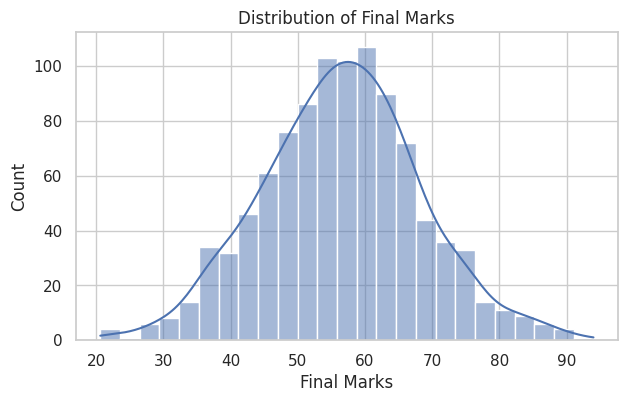

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Final_Marks"], bins=25, kde=True, color="#4C72B0")
plt.title("Distribution of Final Marks")
plt.xlabel("Final Marks")
plt.show()

### 5.2 Correlation heatmap
Correlation tells how strongly two columns move together (from -1 to +1).
- Close to **+1**: when one goes up, the other goes up (e.g. study hours ↑ → marks ↑)
- Close to **-1**: when one goes up, the other goes down (e.g. distraction ↑ → marks ↓)
- Close to **0**: no clear relationship

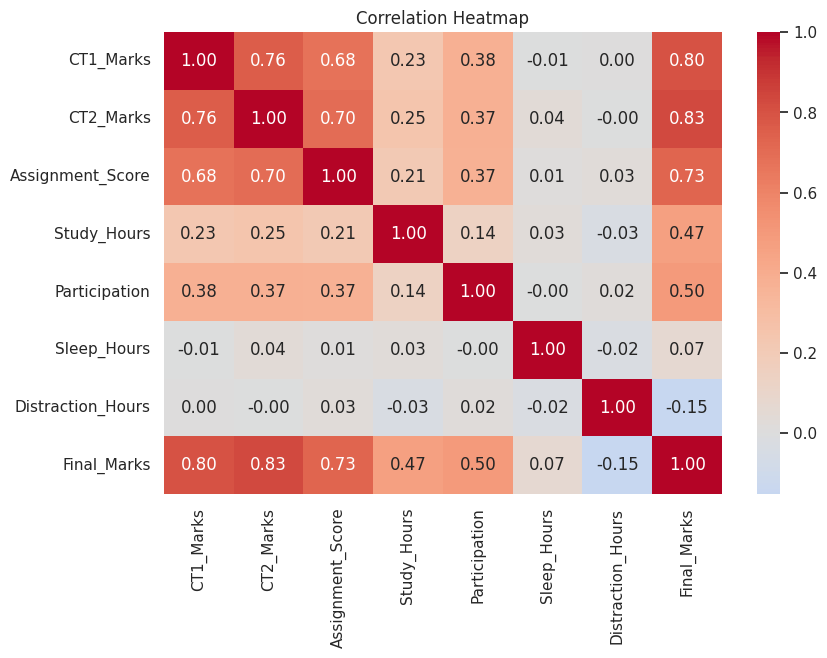

In [7]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

### 5.3 Relationship of key factors with Final Marks
Each dot is a student. The red line shows the overall trend.

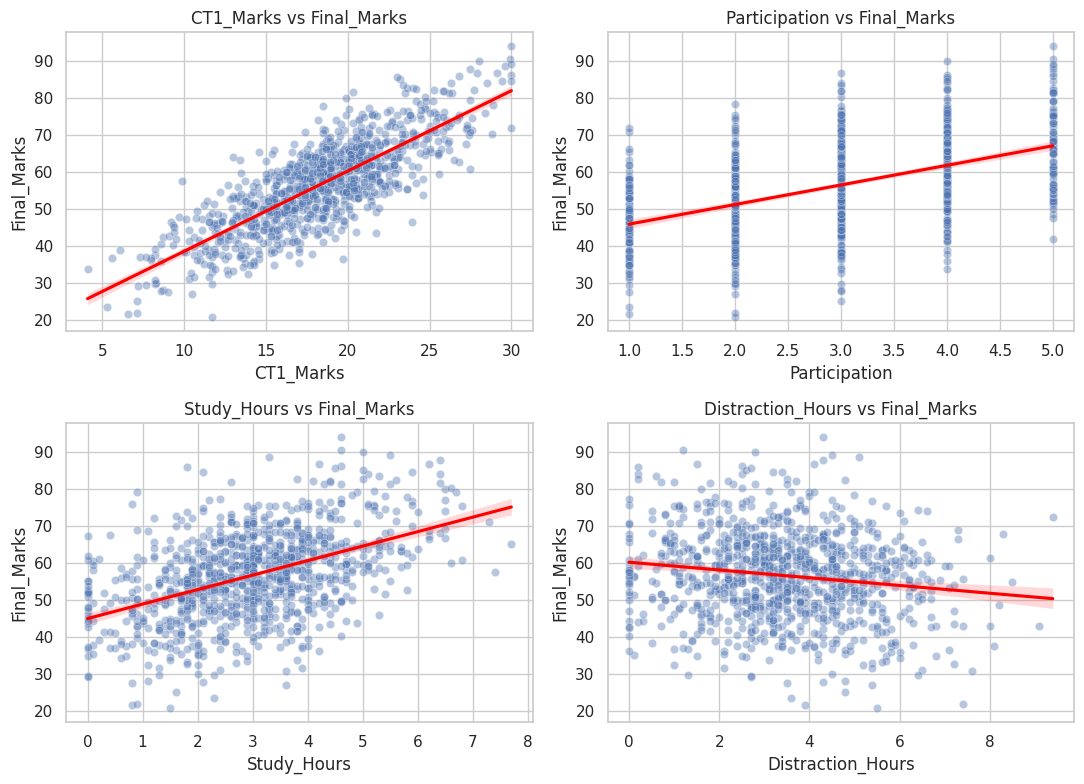

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
prev_col = "Previous_Marks" if "Previous_Marks" in df.columns else [c for c in df.columns if "CT" in c or "Prev" in c][0]
cols_to_plot = [prev_col, "Participation", "Study_Hours", "Distraction_Hours"]

for ax, col in zip(axes.ravel(), cols_to_plot):
    sns.scatterplot(data=df, x=col, y="Final_Marks", alpha=0.4, ax=ax)
    sns.regplot(data=df, x=col, y="Final_Marks", scatter=False, color="red", ax=ax)
    ax.set_title(f"{col} vs Final_Marks")
plt.tight_layout()
plt.show()

## Step 6: Split into training and testing sets
- **X** = the inputs (7 features), **y** = what we want to predict (Final_Marks).
- We train the model on **80%** of students and keep **20%** hidden for testing.
- Testing on unseen students tells us if the model truly learned or just memorised.

In [12]:
TARGET = "Final_Marks"
X = df.drop(columns=[TARGET])
y = df[TARGET]
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training students:", X_train.shape[0])
print("Testing students :", X_test.shape[0])
print("Features used    :", feature_names)

Training students: 800
Testing students : 200
Features used    : ['CT1_Marks', 'CT2_Marks', 'Assignment_Score', 'Study_Hours', 'Participation', 'Sleep_Hours', 'Distraction_Hours']


## Step 7: Train machine learning models
We try **3 different algorithms** and compare them:

| Model | Simple explanation |
|---|---|
| **Linear Regression** | Draws the best straight-line relationship between inputs and marks |
| **Random Forest** | Builds many decision trees and averages their answers |
| **Gradient Boosting** | Builds trees one after another, each fixing the mistakes of the previous one |

`model.fit(X_train, y_train)` is the actual *learning* step.

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained ✅")

Linear Regression trained ✅
Random Forest trained ✅
Gradient Boosting trained ✅


## Step 8: Evaluate the models
We predict marks for the **test students** and compare with their real marks using:
- **MAE (Mean Absolute Error):** average difference in marks. *Lower is better.* (3 means we are off by about 3 marks on average.)
- **RMSE (Root Mean Squared Error):** like MAE but punishes big mistakes more. *Lower is better.*
- **R² score:** how much of the variation in marks the model explains. *Closer to 1 is better.* (0.80 = 80%.)

In [14]:
results = {}
for name, model in models.items():
    pred = model.predict(X_test)
    results[name] = {
        "MAE": round(mean_absolute_error(y_test, pred), 2),
        "RMSE": round(float(np.sqrt(mean_squared_error(y_test, pred))), 2),
        "R2": round(r2_score(y_test, pred), 3),
    }

results_df = pd.DataFrame(results).T
best_name = results_df["R2"].idxmax()
best_model = models[best_name]

print("Model comparison:")
display(results_df)
print(f"\n🏆 Best model: {best_name}")

Model comparison:


,MAE,RMSE,R2
Linear Regression,3.09,3.99,0.900
Random Forest,3.72,4.78,0.857
Gradient Boosting,3.42,4.46,0.875



🏆 Best model: Linear Regression


### 8.1 Visual comparison of models
Shorter bars = smaller error = better model.

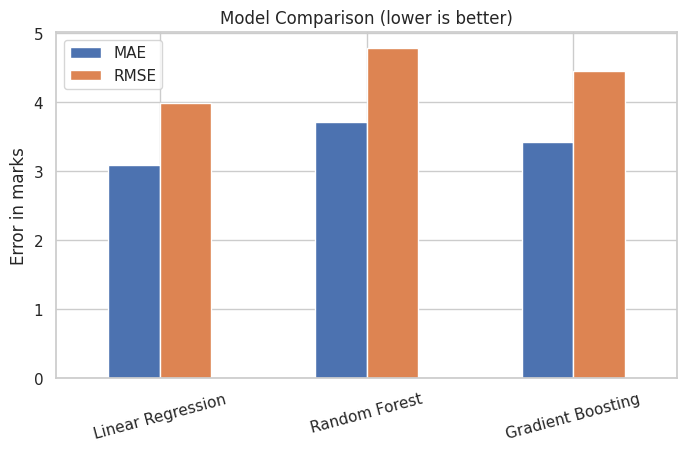

In [15]:
ax = results_df[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 4.5), color=["#4C72B0", "#DD8452"])
ax.set_title("Model Comparison (lower is better)")
ax.set_ylabel("Error in marks")
plt.xticks(rotation=15)
plt.show()

### 8.2 Actual vs Predicted marks (best model)
If the model were perfect, every dot would lie on the red dashed line. The closer the dots are to the line, the better the predictions.

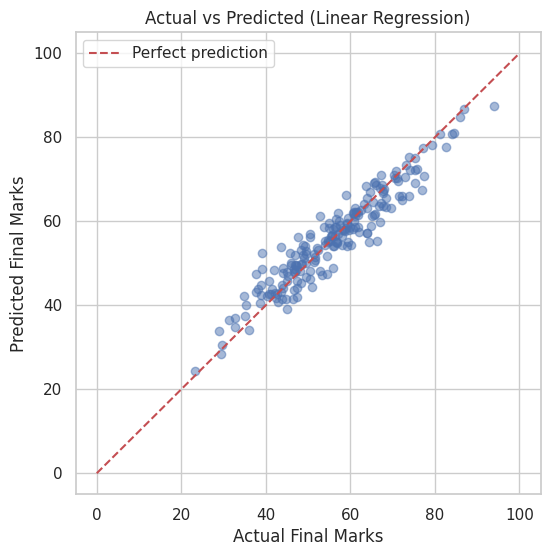

In [16]:
pred_best = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_best, alpha=0.5)
plt.plot([0, 100], [0, 100], "r--", label="Perfect prediction")
plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")
plt.title(f"Actual vs Predicted ({best_name})")
plt.legend()
plt.show()

## Step 9: Feature importance: which factors matter most?
The **Random Forest** model can tell how much each input helped in making predictions. A higher bar means that factor has a stronger relationship with final marks.

This answers the project requirement: *"identify the factors that have an important relationship with the prediction."*

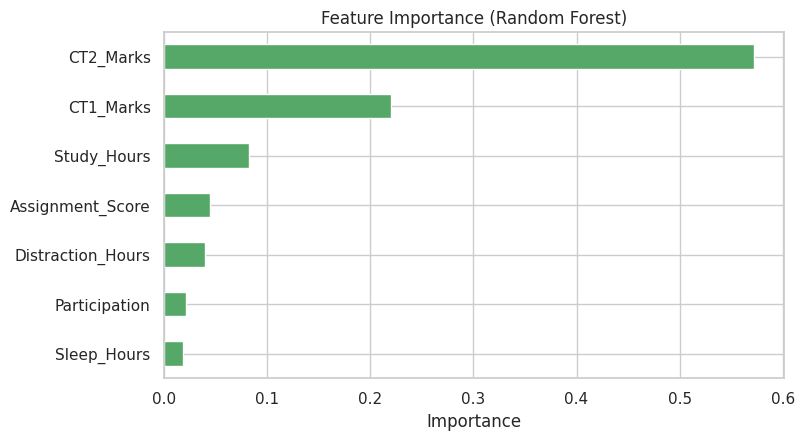

Ranking (most important first):
CT2_Marks            0.572
CT1_Marks            0.220
Study_Hours          0.083
Assignment_Score     0.045
Distraction_Hours    0.040
Participation        0.021
Sleep_Hours          0.018
dtype: float64


In [17]:
importance = pd.Series(models["Random Forest"].feature_importances_, index=feature_names)
importance = importance.sort_values()

plt.figure(figsize=(8, 4.5))
importance.plot(kind="barh", color="#55A868")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()

print("Ranking (most important first):")
print(importance.sort_values(ascending=False).round(3))

## Step 10: Save the trained model
We save the model to a file, so that the web app (`app.py`) can load and use it later without training again.

In [18]:
os.makedirs("models", exist_ok=True)
joblib.dump({"model": best_model, "features": feature_names}, "models/model.joblib")
print(f"Saved '{best_name}' to models/model.joblib ✅")

Saved 'Linear Regression' to models/model.joblib ✅


## Step 11: Predict for a new student (the 7 questions)
**Change the values below** to describe any student, then run the cell. The model predicts the expected final marks and a performance category.

| Question | Allowed values |
|---|---|
| 1. Attendance (%) | 0 – 100 |
| 2. Previous semester marks (%) | 0 – 100 |
| 3. Average assignment score (%) | 0 – 100 |
| 4. Study hours per day | 0 – 10 |
| 5. Class participation | 1 (low) – 5 (high) |
| 6. Sleep hours per night | 3 – 10 |
| 7. Phone / social media hours per day | 0 – 10 |

In [21]:
# ✏️ EDIT THESE 7 ANSWERS
ct1_marks         = 18
ct2_marks         = 19
assignment_score  = 75
study_hours       = 3.5
participation     = 4
sleep_hours       = 7
distraction_hours = 3

# ---------- prediction ----------
student = pd.DataFrame([{
    "CT1_Marks": ct1_marks,
    "CT2_Marks": ct2_marks,
    "Assignment_Score": assignment_score,
    "Study_Hours": study_hours,
    "Participation": participation,
    "Sleep_Hours": sleep_hours,
    "Distraction_Hours": distraction_hours,
}])[feature_names]

marks = float(np.clip(best_model.predict(student)[0], 0, 100))

def grade_category(m):
    if m >= 80: return "Excellent"
    if m >= 65: return "Good"
    if m >= 50: return "Average"
    return "At Risk"

print(f"📊 Predicted Final Marks : {marks:.1f} / 100")
print(f"🏷️  Performance Category : {grade_category(marks)}")

# simple suggestions based on the answers
tips = []
if study_hours < 2.5: tips.append("Add more daily study time.")
if distraction_hours > 4: tips.append("Reduce phone / social media time.")
if sleep_hours < 6: tips.append("Aim for 7-8 hours of sleep.")
if assignment_score < 60: tips.append("Improve assignment submissions.")
print("\nSuggestions:", tips if tips else "Your habits look strong. Keep it up! ✅")

📊 Predicted Final Marks : 60.5 / 100
🏷️  Performance Category : Average

Suggestions: Your habits look strong. Keep it up! ✅


### Try two extreme students
A good model should give a high score to a hard-working student and a low score to a struggling one.

In [23]:
strong = dict(CT1_Marks=26, CT2_Marks=27, Assignment_Score=88, Study_Hours=5,
              Participation=5, Sleep_Hours=7.5, Distraction_Hours=1.5)
weak   = dict(CT1_Marks=12, CT2_Marks=11, Assignment_Score=45, Study_Hours=1,
              Participation=1, Sleep_Hours=4.5, Distraction_Hours=7)

for label, s in [("Strong student", strong), ("Weak student", weak)]:
    m = float(np.clip(best_model.predict(pd.DataFrame([s])[feature_names])[0], 0, 100))
    print(f"{label:15s} → {m:5.1f} / 100  ({grade_category(m)})")

Strong student  →  83.0 / 100  (Excellent)
Weak student    →  28.2 / 100  (At Risk)


## Step 12: Conclusion
- We built a **regression model** that predicts a student's final marks from 7 factors.
- Three algorithms were compared using **MAE, RMSE and R²**; the best one was saved.
- **Previous marks, assignment score, study hours and attendance** have the strongest relationship with final marks, while too much phone/social media time lowers marks.
- The saved model is used by the Streamlit web app (`app.py`) to give predictions to users.

**Future scope:** use real college data, add more features (health, family support), try deep learning, deploy the app online and add a teacher dashboard.